# Hessian-vector products

The Hessian $\mathbf H$ of the FWI misfit $J(\mathbf m)=\tfrac12\|\mathbf d(\mathbf m)-\mathbf d_{\rm obs}\|^2$
is never formed; what Newton-type optimizers, resolution analysis and uncertainty estimates need is
its action $\mathbf H\mathbf h$ on a direction $\mathbf h$. With the Jacobian
$\mathbf J=\partial\mathbf d/\partial\mathbf m$ and the residual $\mathbf r=\mathbf d-\mathbf d_{\rm obs}$,

$$\mathbf H\mathbf h=\mathbf J^{\mathsf T}\mathbf J\,\mathbf h+\sum_i r_i\,\frac{\partial^2 d_i}{\partial\mathbf m^2}\,\mathbf h ,$$

where the first term is the Gauss-Newton product and the second one vanishes when the data are fitted.

`sweep` gives $\mathbf H\mathbf h$ in four ways, which differ by orders of magnitude in memory and time:

| route | what it computes | runs with | cost of one product |
|---|---|---|---|
| double backward | $\mathbf H\mathbf h$, exact | `impl='eager'`, `memory=Full()` or `Ckpt()`, `use_compile=False` | the whole autograd tape of the time loop |
| difference of two gradients | $\mathbf H\mathbf h$, to $O(\varepsilon^2)$ | every `impl` and memory strategy | two gradients |
| Born forward, then a gradient | $\mathbf J^{\mathsf T}\mathbf J\mathbf h$, exact | every `impl` and memory strategy | one Born forward and one gradient |
| first-order gradient of the Born system | $\mathbf H\mathbf h$, exact | equations with a Born twin (`AcousticBorn`); `impl='c'` with `Full()` or `BoundarySaving()`, or compiled eager | one Born forward, one forward, and their gradients |

This notebook

1. computes the exact product by double backward and shows what that costs;
2. shows the paths that refuse `create_graph=True`, and their error;
3. computes the same product as a difference of two `impl='c'` gradients with boundary saving,
   and how to choose the step $\varepsilon$;
4. computes the Gauss-Newton product with `AcousticBorn`;
5. computes the exact product from first derivatives of the Born system, with `impl='c'` and
   with the compiled eager step;
6. compares the routes in accuracy, memory and time;
7. assembles the full Hessian of a small model and looks at its diagonal and eigenvalues.

## 1. Model and data

In [1]:
import sys, pathlib, time

_repo = pathlib.Path().resolve().parents[1]     # docs/notebooks/ -> repo root
if str(_repo / "src") not in sys.path:
    sys.path.insert(0, str(_repo / "src"))

import numpy as np
import torch
import matplotlib.pyplot as plt

from sweep.equations import Acoustic, AcousticBorn
from sweep.propagator import BoundarySaving, Full, PropTorch
from sweep.propagator.options import EagerOptions

torch.backends.cudnn.allow_tf32 = False         # eager convolutions in fp32 on Ampere and later
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)

device: cuda


In [2]:
nz, nx, dh = 100, 200, 10.0                     # 1 km deep x 2 km, 10 m grid
dt, nt, f0 = 1e-3, 1000, 10.0
abcn, order = 30, 4
z = np.arange(nz, dtype=np.float32)[:, None] * dh + np.zeros((1, nx), np.float32)
x = np.arange(nx, dtype=np.float32)[None, :] * dh + np.zeros((nz, 1), np.float32)

v0 = (1600.0 + 0.8 * z).astype(np.float32)                                   # initial model
v_true = (v0 + 150.0 * np.exp(-((z - 500) ** 2 + (x - 1000) ** 2) / (2 * 80.0 ** 2))).astype(np.float32)

src_x = np.arange(20, nx - 20, 40)              # 4 shots every 400 m
nshots = len(src_x)
sources = np.stack([src_x, np.full(nshots, 2)], 1)                           # (x, z)
rec_x = np.arange(2, nx - 2, 2)                 # 98 receivers every 20 m
receivers = np.repeat(np.stack([rec_x, np.full_like(rec_x, 2)], 1)[None], nshots, 0)

t = np.arange(nt) * dt
a = (np.pi * f0 * (t - 1.2 / f0)) ** 2
T = lambda arr: torch.tensor(arr, device=device)
w = T(((1 - 2 * a) * np.exp(-a)).astype(np.float32))                         # Ricker, 10 Hz
m0 = T(v0)


def acoustic(impl, memory):
    kw = dict(shape=(nz, nx), dh=dh, dt=dt, nt=nt, abcn=abcn, impl=impl, memory=memory,
              source_type=["h1"], receiver_type=["h1"], dev=device)
    if impl == "eager":
        kw["eager_options"] = EagerOptions(use_compile=False)
    return PropTorch(Acoustic(spatial_order=order, device=device), **kw)


c_bs = acoustic("c", BoundarySaving())
with torch.no_grad():
    d_obs = c_bs(w, sources, receivers, models=[T(v_true)])
print("observed data (shots, nt, receivers, 1):", tuple(d_obs.shape))


def misfit(prop, m):
    return 0.5 * ((prop(w, sources, receivers, models=[m]) - d_obs) ** 2).sum()


def gradient(prop, m):
    m = m.clone().requires_grad_(True)
    return torch.autograd.grad(misfit(prop, m), m)[0]

observed data (shots, nt, receivers, 1): (4, 1000, 98, 1)


We use two directions. $\mathbf h_{\rm psf}$ is a small Gaussian at the centre of the anomaly, so
$\mathbf H\mathbf h_{\rm psf}$ is the point-spread function of the Hessian there. $\mathbf h_{\rm rand}$ is
white noise, which weights every scale of the model. Both are zero on the two outermost cells:
the model gradient of an outermost cell is the cropped one of the padded model, which a
difference of gradients does not reproduce.

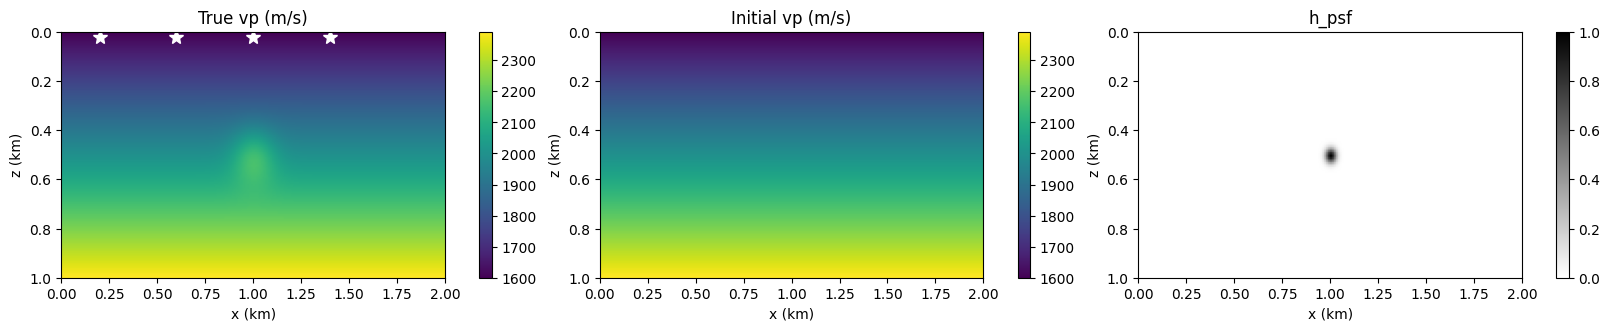

In [3]:
h_psf = T(np.exp(-((z - 500) ** 2 + (x - 1000) ** 2) / (2 * 20.0 ** 2)).astype(np.float32))
ring = torch.zeros(nz, nx, device=device)
ring[2:-2, 2:-2] = 1.0
h_rand = torch.randn(nz, nx, generator=torch.Generator().manual_seed(0)).to(device) * ring

extent = [0, nx * dh / 1e3, nz * dh / 1e3, 0]
fig, ax = plt.subplots(1, 3, figsize=(16, 3.2), constrained_layout=True)
vrange = dict(vmin=float(v_true.min()), vmax=float(v_true.max()))          # one scale for both models
for a_, img, title, kw in [(ax[0], v_true, "True vp (m/s)", dict(cmap="viridis", **vrange)),
                           (ax[1], v0, "Initial vp (m/s)", dict(cmap="viridis", **vrange)),
                           (ax[2], h_psf.cpu().numpy(), "h_psf", dict(cmap="gray_r"))]:
    im = a_.imshow(img, extent=extent, aspect="auto", **kw)
    a_.set_title(title); a_.set_xlabel("x (km)"); a_.set_ylabel("z (km)")
    fig.colorbar(im, ax=a_)
ax[0].plot(src_x * dh / 1e3, np.full(nshots, 0.02), "w*", ms=10)
plt.show()

## 2. Exact product by double backward

The uncompiled eager step is plain PyTorch, so autograd can differentiate the gradient once more.
We take the gradient with `create_graph=True` and differentiate $\mathbf g\cdot\mathbf h$; the tape of the
first backward is kept, so further directions reuse it with `retain_graph=True`. The requirements are

* `impl='eager'` with `eager_options=EagerOptions(use_compile=False)`: torch.compile builds the
  step's backward without a double backward;
* `memory=Full()` or `memory=Ckpt()`: `create_graph=True` keeps the recomputed chunks on the tape,
  so checkpointing does not reduce the memory here;
* `torch.backends.cudnn.allow_tf32 = False` on Ampere and later GPUs: in TF32 the product is off by
  several percent.

We also compute the exact Jacobian product $\mathbf J\mathbf h_{\rm psf}$ on the same tape, by differentiating
$\mathbf J^{\mathsf T}\mathbf u$ with respect to a dummy residual $\mathbf u$; Section 5 checks the Born route against it.

In [4]:
eager = acoustic("eager", Full())


def peak_mib(start):
    return (torch.cuda.max_memory_allocated() - start) / 2**20 if device.type == "cuda" else float("nan")


def sync():
    if device.type == "cuda":
        torch.cuda.synchronize()


if device.type == "cuda":
    torch.cuda.empty_cache(); torch.cuda.reset_peak_memory_stats()
start = torch.cuda.memory_allocated() if device.type == "cuda" else 0
t0 = time.perf_counter()
m = m0.clone().requires_grad_(True)
rec = eager(w, sources, receivers, models=[m])
(g,) = torch.autograd.grad(0.5 * ((rec - d_obs) ** 2).sum(), m, create_graph=True)
hv_exact = {name: torch.autograd.grad((g * h).sum(), m, retain_graph=True)[0]
            for name, h in [("psf", h_psf), ("rand", h_rand)]}
u = torch.zeros_like(rec, requires_grad=True)
(jtu,) = torch.autograd.grad(rec, m, grad_outputs=u, create_graph=True)
(jh_exact,) = torch.autograd.grad((jtu * h_psf).sum(), u, retain_graph=True)   # J h_psf
(gn_exact,) = torch.autograd.grad(rec, m, grad_outputs=jh_exact)               # J^T J h_psf
sync()
cost = {"double backward (one tape)": (time.perf_counter() - t0, peak_mib(start))}
del rec, g, jtu, u, m
print("double backward: %.1f s, peak %.0f MiB for two products and one Gauss-Newton product"
      % cost["double backward (one tape)"])

double backward: 210.1 s, peak 12735 MiB for two products and one Gauss-Newton product


## 3. The paths that refuse `create_graph=True`

`impl='c'`, eager boundary saving, the compiled eager step, domain decomposition and registered
gradient-mode imaging conditions compute their backward outside the autograd tape. Under
`create_graph=True` they raise at once and say what works; a gradient without a graph would
otherwise fail later, or return only the Hessian of a regularizer on the tape.

In [5]:
for name, prop in [("impl='c'", c_bs), ("eager + BoundarySaving()", acoustic("eager", BoundarySaving()))]:
    m = m0.clone().requires_grad_(True)
    try:
        torch.autograd.grad(misfit(prop, m), m, create_graph=True)
    except RuntimeError as err:
        print(f"{name}:\n  {str(err)[:230]}...\n")

impl='c':
  impl='c' gives first derivatives only and is not twice-differentiable: its backward is the compiled adjoint, which autograd cannot differentiate again. create_graph=True (Hessian-vector products, higher-order gradients) needs the ...



eager + BoundarySaving():
  impl='eager' with memory=BoundarySaving() gives first derivatives only and is not twice-differentiable: its backward reconstructs each step's input from the saved boundary and re-runs the step on detached copies. create_graph=True...



## 4. Difference of two gradients

The central difference

$$\mathbf H\mathbf h\approx\frac{\mathbf g(\mathbf m+\varepsilon\mathbf h)-\mathbf g(\mathbf m-\varepsilon\mathbf h)}{2\varepsilon}$$

needs two gradients and nothing else, so it runs with `impl='c'` and boundary saving at the memory of
one gradient. Its error has two parts: the truncation error, which grows as $\varepsilon^2$, and the
single-precision round-off of the gradients, which grows as $1/\varepsilon$. We scan $\varepsilon$ against
the exact products of Section 2.

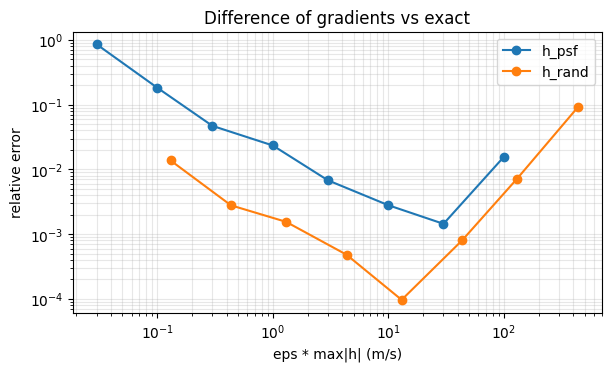

h_psf: best eps*max|h| = 30.0 m/s, relative error 1.4e-03
h_rand: best eps*max|h| = 13.0 m/s, relative error 9.7e-05


In [6]:
def hv_difference(h, eps, prop=c_bs):
    return (gradient(prop, m0 + eps * h) - gradient(prop, m0 - eps * h)) / (2 * eps)


rel = lambda a_, b_: float((a_ - b_).norm() / b_.norm())
eps_scan = [0.03, 0.1, 0.3, 1.0, 3.0, 10.0, 30.0, 100.0]
errors = {name: [rel(hv_difference(h, e), hv_exact[name]) for e in eps_scan]
          for name, h in [("psf", h_psf), ("rand", h_rand)]}

fig, ax = plt.subplots(figsize=(6, 3.6), constrained_layout=True)
for name, h in [("psf", h_psf), ("rand", h_rand)]:
    dv = [e * float(h.abs().max()) for e in eps_scan]          # largest velocity change, m/s
    ax.loglog(dv, errors[name], "o-", label=f"h_{name}")
ax.set_xlabel("eps * max|h| (m/s)"); ax.set_ylabel("relative error")
ax.set_title("Difference of gradients vs exact"); ax.grid(True, which="both", alpha=0.3); ax.legend()
plt.show()
for name in errors:
    best = int(np.argmin(errors[name]))
    print(f"h_{name}: best eps*max|h| = {eps_scan[best] * float(dict(psf=h_psf, rand=h_rand)[name].abs().max()):.1f} m/s,"
          f" relative error {errors[name][best]:.1e}")

As shown in the figure, the error first falls as $1/\varepsilon$ (round-off) and then rises as $\varepsilon^2$
(truncation). It is smallest when the largest velocity change $\varepsilon\max|\mathbf h|$ is about ten to a few
tens of m/s, 0.5 to 2 % of the velocity here, where the product agrees with the exact one to about
$10^{-3}$ for $\mathbf h_{\rm psf}$ and $10^{-4}$ for $\mathbf h_{\rm rand}$. The minimum depends on the direction and the
model, so for a new problem we recommend a short scan of this kind, with two or three values of
$\varepsilon$, before choosing the step.

## 5. Gauss-Newton product with a Born forward

`AcousticBorn` steps the background field and the scattered field of the same scheme together, and
its scattered step is the derivative of the `Acoustic` step. Its perturbation `mp` is the relative
change of $v^2$, so a velocity direction $\mathbf h$ enters as `mp` $=2\mathbf h/\mathbf m$, and its record is
$\mathbf J\mathbf h$. A gradient with $\mathbf J\mathbf h$ in place of the residual then gives
$\mathbf J^{\mathsf T}\mathbf J\mathbf h$. Both steps run with `impl='c'` and boundary saving. The product drops
the residual term, so it is positive semi-definite, which is what the conjugate-gradient inner loop
of a Gauss-Newton method needs.

In [7]:
def acoustic_born():
    return PropTorch(AcousticBorn(spatial_order=order, device=device), shape=(nz, nx), dh=dh, dt=dt,
                     nt=nt, abcn=abcn, impl="c", memory=BoundarySaving(), source_type=["h1"],
                     receiver_type=["sh1"], dev=device)


born = acoustic_born()


def jacobian_product(h, born=born):
    with torch.no_grad():
        return born(w, sources, receivers, models=[m0, 2 * h / m0])


def hv_gauss_newton(h, prop=c_bs, born=born):
    m = m0.clone().requires_grad_(True)
    rec = prop(w, sources, receivers, models=[m])
    return torch.autograd.grad(rec, m, grad_outputs=jacobian_product(h, born))[0]


print("J h_psf, Born vs exact:           %.1e" % rel(jacobian_product(h_psf), jh_exact))
print("J^T J h_psf, Born route vs exact: %.1e" % rel(hv_gauss_newton(h_psf), gn_exact))
print("J^T J h_psf vs full H h_psf:      %.1e  (the residual term)" % rel(gn_exact, hv_exact["psf"]))

J h_psf, Born vs exact:           1.7e-04
J^T J h_psf, Born route vs exact: 1.4e-04
J^T J h_psf vs full H h_psf:      3.6e-02  (the residual term)


## 6. Exact product from first derivatives of the Born system

The second-order term needs no second derivative either. With $\mathbf s=\mathbf J\mathbf h$ and $\mathbf r$ held
fixed, the scalar

$$\psi(\mathbf m)=\langle\mathbf d(\mathbf m),\,\mathbf s\rangle+\langle\mathbf J(\mathbf m)\mathbf h,\,\mathbf r\rangle$$

has the gradient

$$\nabla\psi=\mathbf J^{\mathsf T}\mathbf s+\Big(\frac{\partial(\mathbf J\mathbf h)}{\partial\mathbf m}\Big)^{\mathsf T}\mathbf r
=\mathbf J^{\mathsf T}\mathbf J\mathbf h+\sum_i r_i\,\frac{\partial^2 d_i}{\partial\mathbf m^2}\,\mathbf h=\mathbf H\mathbf h .$$

$\mathbf J(\mathbf m)\mathbf h$ is the Born record, so the second term is the gradient of the Born data
with respect to the background velocity, which `AcousticBorn` returns with `impl='c'` in the full
and boundary-saving modes. The direction enters through `mp = 2h/m`, which depends on $\mathbf m$ as well;
autograd takes that dependence into account when `mp` is computed from the model tensor. Only first
derivatives are taken, so the route runs with `impl='c'`, with boundary saving, and with the
compiled eager step. It costs one Born forward, one forward and their two backwards. This is the
second-order adjoint method: deepwave computes the same two extra wavefields in the double backward
of its scalar propagator. The eager `AcousticBorn` takes the first derivatives of `Acoustic`'s CPML,
so the compiled eager product agrees with the double backward to round-off. The `impl='c'` kernels
of the 2-D `AcousticBorn` take the CPML term $\partial_x(a\psi)$ by the product rule where those of
`Acoustic` take one fused stencil, which leaves the `impl='c'` products about $10^{-4}$ off here, more
in a thinner PML.

In [8]:
def hv_born_system(h, prop, born):
    m = m0.clone().requires_grad_(True)
    s = born(w, sources, receivers, models=[m, 2 * h / m])      # J h, on the tape of m
    d = prop(w, sources, receivers, models=[m])
    psi = (d * s.detach()).sum() + (s * (d - d_obs).detach()).sum()
    return torch.autograd.grad(psi, m)[0]


def eager_compiled(equation, receiver):
    return PropTorch(equation(spatial_order=order, device=device), shape=(nz, nx), dh=dh, dt=dt, nt=nt,
                     abcn=abcn, impl="eager", memory=Full(), source_type=["h1"],
                     receiver_type=[receiver], dev=device, eager_options=EagerOptions(use_compile=True))


hv_bs = {name: hv_born_system(h, c_bs, born) for name, h in [("psf", h_psf), ("rand", h_rand)]}
for name in hv_bs:
    print(f"h_{name}: impl='c' + BoundarySaving vs double backward: {rel(hv_bs[name], hv_exact[name]):.1e}")
if device.type == "cuda":
    eager_pair = (eager_compiled(Acoustic, "h1"), eager_compiled(AcousticBorn, "sh1"))
    hv_compiled = hv_born_system(h_psf, *eager_pair)
    print(f"h_psf: compiled eager vs double backward:          {rel(hv_compiled, hv_exact['psf']):.1e}")

h_psf: impl='c' + BoundarySaving vs double backward: 1.5e-04
h_rand: impl='c' + BoundarySaving vs double backward: 1.3e-05


sweep: torch.compile is compiling the AcousticBorn step for 4 shots on a 100x200 grid (with gradients); the first call on each new grid size takes seconds to a few minutes (cached on disk for later runs). EagerOptions(use_compile=False) runs uncompiled instead.


sweep: torch.compile is compiling the Acoustic step for 4 shots on a 100x200 grid (with gradients)


h_psf: compiled eager vs double backward:          5.5e-06


## 7. Comparison

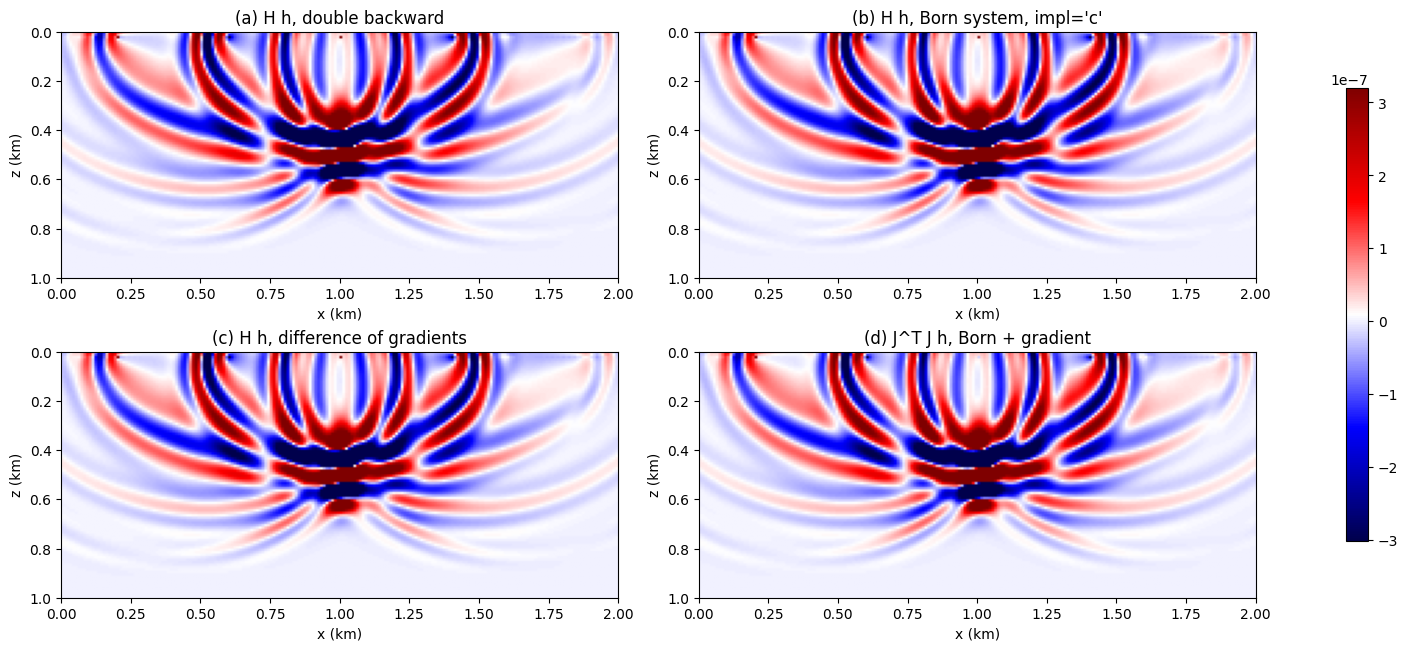

In [9]:
eps_psf = eps_scan[int(np.argmin(errors["psf"]))] # the best step of Section 4 (max|h_psf| = 1)
hv_fd = hv_difference(h_psf, eps_psf)
hv_gn = hv_gauss_newton(h_psf)

panels = [(hv_exact["psf"], "(a) H h, double backward"),
          (hv_bs["psf"], "(b) H h, Born system, impl='c'"),
          (hv_fd, "(c) H h, difference of gradients"),
          (hv_gn, "(d) J^T J h, Born + gradient")]
lo, hi = np.percentile(hv_exact["psf"].cpu().numpy()[12:], [2, 98])          # below the acquisition rows
fig, ax = plt.subplots(2, 2, figsize=(14, 6.4), constrained_layout=True)
for a_, (img, title) in zip(ax.flat, panels):
    im = a_.imshow(img.cpu().numpy(), cmap="seismic", vmin=lo, vmax=hi, extent=extent, aspect="auto")
    a_.set_title(title); a_.set_xlabel("x (km)"); a_.set_ylabel("z (km)")
fig.colorbar(im, ax=ax, shrink=0.8)
plt.show()

All panels share the colour scale of (a). The point-spread function (a) is not a point: the
Gaussian is spread along the wavepaths that connect it to the sources and receivers at the surface,
because surface data constrain the model mainly along those paths. The Born-system product (b) and
the difference of gradients (c) reproduce (a). The Gauss-Newton product (d) differs from (a) by the
residual term, 3.6 % of the norm in this model.

We now time one product of each route. The `impl='c'` propagators are built inside the measurement
and the peak memory is taken on their first call, so it includes their buffers.

In [10]:
def measure(fn, repeat=3):
    if device.type == "cuda":
        torch.cuda.empty_cache(); torch.cuda.reset_peak_memory_stats()
    start = torch.cuda.memory_allocated() if device.type == "cuda" else 0
    fn()                                                       # first call: peak memory
    mib = peak_mib(start)
    sync(); t0 = time.perf_counter()
    for _ in range(repeat):
        fn()
    sync()
    return (time.perf_counter() - t0) / repeat, mib


del eager                                        # free the eager tape's workspace
cost["difference of gradients"] = measure(
    lambda: hv_difference(h_psf, eps_psf, acoustic("c", BoundarySaving())))
cost["Born + gradient"] = measure(
    lambda: hv_gauss_newton(h_psf, acoustic("c", BoundarySaving()), acoustic_born()))
cost["Born system, impl='c'"] = measure(
    lambda: hv_born_system(h_psf, acoustic("c", BoundarySaving()), acoustic_born()))
if device.type == "cuda":
    cost["Born system, compiled eager"] = measure(lambda: hv_born_system(h_psf, *eager_pair))
print(f"{'route':<30}{'time (s)':>10}{'peak (MiB)':>12}")
for name, (sec, mib) in cost.items():
    print(f"{name:<30}{sec:>10.2f}{mib:>12.0f}")

route                           time (s)  peak (MiB)
double backward (one tape)        210.14       12735
difference of gradients             0.13          44
Born + gradient                     0.10          56
Born system, impl='c'               0.20         125
Born system, compiled eager         2.06        2011


The first row is the tape of Section 2, which served two products $\mathbf H\mathbf h$ and one $\mathbf J^{\mathsf T}\mathbf J\mathbf h$;
the other rows are one product each, and the compiled eager row keeps the full wavefield. The double
backward keeps every step of the time loop and of its first backward on the tape, so its memory grows
with the number of time steps times the grid, and the uncompiled step is slow. In this model the
tape takes gigabytes and minutes, against a fraction of a second and tens of megabytes for the
`impl='c'` routes with boundary saving. The exact Born-system product costs about as much as the
difference of two gradients and has no step to choose.

## 8. The full Hessian of a small model

On a small model the Hessian can be assembled column by column, $\mathbf H\mathbf e_j$ for every unit vector
$\mathbf e_j$, with the Born-system product of Section 6. We take a 300 m x 400 m model on a 10 m grid with
three sources at 15 Hz, and parameterize it by the cells off the two outermost rings, 936 unknowns.
The same loop gives the Gauss-Newton matrix from its first term.

In [11]:
snz, snx, snt, sf0 = 30, 40, 500, 15.0
sz = np.arange(snz, dtype=np.float32)[:, None] * dh + np.zeros((1, snx), np.float32)
sx = np.arange(snx, dtype=np.float32)[None, :] * dh + np.zeros((snz, 1), np.float32)
sv0 = (1600.0 + 1.0 * sz).astype(np.float32)
sv_true = (sv0 + 120.0 * np.exp(-((sz - 170) ** 2 + (sx - 200) ** 2) / (2 * 40.0 ** 2))).astype(np.float32)
s_sources = np.stack([np.array([5, 20, 34]), np.full(3, 2)], 1)
s_rec_x = np.arange(2, snx - 2)
s_receivers = np.repeat(np.stack([s_rec_x, np.full_like(s_rec_x, 2)], 1)[None], 3, 0)
ta = (np.pi * sf0 * (np.arange(snt) * dt - 1.2 / sf0)) ** 2
s_w = T(((1 - 2 * ta) * np.exp(-ta)).astype(np.float32))
s_m0 = T(sv0)


def small(equation, receiver):
    return PropTorch(equation(spatial_order=order, device=device), shape=(snz, snx), dh=dh, dt=dt,
                     nt=snt, abcn=20, impl="c", memory=BoundarySaving(), source_type=["h1"],
                     receiver_type=[receiver], dev=device)


s_fwd, s_born = small(Acoustic, "h1"), small(AcousticBorn, "sh1")
with torch.no_grad():
    s_obs = s_fwd(s_w, s_sources, s_receivers, models=[T(sv_true)])
    s_res = s_fwd(s_w, s_sources, s_receivers, models=[s_m0]) - s_obs

inner = np.zeros((snz, snx), bool)
inner[2:-2, 2:-2] = True
cells = np.flatnonzero(inner)
n = len(cells)
H = np.zeros((n, n))
GN = np.zeros((n, n))
t0 = time.perf_counter()
for j, k in enumerate(cells):
    e = torch.zeros(snz * snx, device=device)
    e[k] = 1.0
    m = s_m0.clone().requires_grad_(True)
    s = s_born(s_w, s_sources, s_receivers, models=[m, 2 * e.view(snz, snx) / m])
    d = s_fwd(s_w, s_sources, s_receivers, models=[m])
    gn = torch.autograd.grad((d * s.detach()).sum(), m)[0]          # J^T J e_j
    second = torch.autograd.grad((s * s_res).sum(), m)[0]           # residual term
    GN[:, j] = gn.flatten()[cells].double().cpu().numpy()
    H[:, j] = (gn + second).flatten()[cells].double().cpu().numpy()
print(f"{n} columns in {time.perf_counter() - t0:.0f} s")
asym = lambda A: np.linalg.norm(A - A.T) / np.linalg.norm(A)
print(f"asymmetry ||H - H^T|| / ||H||: {asym(H):.1e} (H), {asym(GN):.1e} (Gauss-Newton)")

936 columns in 47 s
asymmetry ||H - H^T|| / ||H||: 5.0e-05 (H), 5.0e-05 (Gauss-Newton)


The matrices are symmetric to single precision. We check one column against the double backward
through the eager step, and then look at the matrix, its diagonal and its eigenvalues.

column 468 vs double backward: 6.0e-04


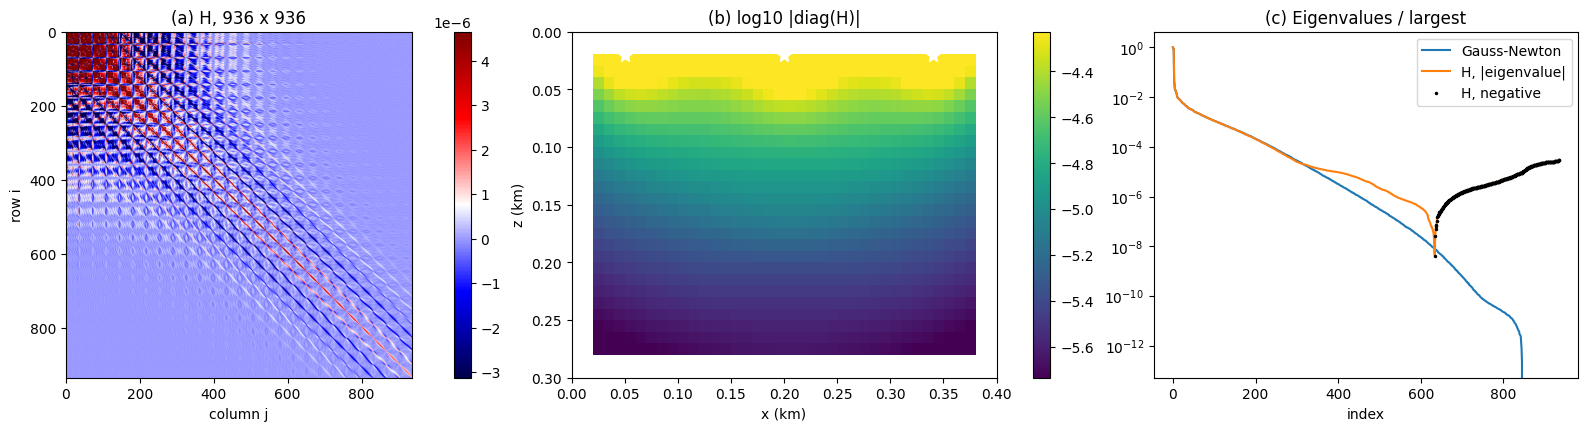

negative eigenvalues: H 302 (smallest -3.1e-05 of the largest), Gauss-Newton 90 (smallest -8.6e-11)


In [12]:
s_eager = PropTorch(Acoustic(spatial_order=order, device=device), shape=(snz, snx), dh=dh, dt=dt, nt=snt,
                    abcn=20, impl="eager", memory=Full(), source_type=["h1"], receiver_type=["h1"],
                    dev=device, eager_options=EagerOptions(use_compile=False))
m = s_m0.clone().requires_grad_(True)
rec = s_eager(s_w, s_sources, s_receivers, models=[m])
(g,) = torch.autograd.grad(0.5 * ((rec - s_obs) ** 2).sum(), m, create_graph=True)
j = n // 2
e = torch.zeros(snz * snx, device=device)
e[cells[j]] = 1.0
col = torch.autograd.grad((g * e.view(snz, snx)).sum(), m)[0].flatten()[cells].double().cpu().numpy()
print(f"column {j} vs double backward: {np.linalg.norm(H[:, j] - col) / np.linalg.norm(col):.1e}")

lam_h = np.linalg.eigvalsh(0.5 * (H + H.T))[::-1]
lam_gn = np.linalg.eigvalsh(0.5 * (GN + GN.T))[::-1]
diag = np.full((snz, snx), np.nan)
diag.flat[cells] = np.diag(H)
s_extent = [0, snx * dh / 1e3, snz * dh / 1e3, 0]

fig, ax = plt.subplots(1, 3, figsize=(16, 4.2), constrained_layout=True)
lo, hi = np.percentile(H, [2, 98])
im = ax[0].imshow(H, cmap="seismic", vmin=lo, vmax=hi)
ax[0].set_title("(a) H, 936 x 936"); ax[0].set_xlabel("column j"); ax[0].set_ylabel("row i")
fig.colorbar(im, ax=ax[0])
log_diag = np.log10(np.abs(diag))
lo, hi = np.nanpercentile(log_diag[4:], [2, 98])                        # below the acquisition rows
im = ax[1].imshow(log_diag, cmap="viridis", vmin=lo, vmax=hi, extent=s_extent, aspect="auto")
ax[1].plot(s_sources[:, 0] * dh / 1e3, s_sources[:, 1] * dh / 1e3, "w*", ms=10)
ax[1].set_title("(b) log10 |diag(H)|"); ax[1].set_xlabel("x (km)"); ax[1].set_ylabel("z (km)")
fig.colorbar(im, ax=ax[1])
ax[2].semilogy(lam_gn / lam_gn[0], label="Gauss-Newton")
ax[2].semilogy(np.abs(lam_h) / lam_h[0], label="H, |eigenvalue|")
neg = lam_h < 0
ax[2].semilogy(np.flatnonzero(neg), np.abs(lam_h[neg]) / lam_h[0], "k.", ms=3, label="H, negative")
ax[2].set_title("(c) Eigenvalues / largest"); ax[2].set_xlabel("index"); ax[2].legend()
plt.show()
print(f"negative eigenvalues: H {int(neg.sum())} (smallest {lam_h.min() / lam_h[0]:.1e} of the largest), "
      f"Gauss-Newton {int((lam_gn < 0).sum())} (smallest {lam_gn.min() / lam_gn[0]:.1e})")

The cells are numbered row by row from the surface down, 36 per row. A cell's coupling with its
lateral neighbours therefore lies next to the diagonal of (a), and its coupling with the rows above
and below lies in bands 36 columns apart, which gives the striped pattern. The largest entries are
in the top-left block, which belongs to the shallow cells. The diagonal (b) decreases by more than
an order of magnitude from the surface to the bottom of the model and varies little laterally under
this dense receiver line; this depth decay is what a diagonal (illumination) preconditioner
compensates. The eigenvalues (c) of the Gauss-Newton matrix fall from 1 to $10^{-12}$ of the largest,
so most directions in the model are poorly constrained by these data; its smallest eigenvalues,
about $-10^{-10}$ of the largest, are round-off. The full Hessian follows the Gauss-Newton spectrum
for the well-constrained directions, but about a third of its eigenvalues are negative and reach
$-3\times10^{-5}$ of the largest, far above that round-off: the residual term is indefinite. A Newton
method on $\mathbf H$ therefore needs a conjugate-gradient loop that detects negative curvature, while a
Gauss-Newton method does not.

## 9. Which route to take

* For tests, small models and second derivatives of a loss with other autograd terms, the double
  backward gives the exact product and every parameter the propagator differentiates.
* For an equation with a Born twin (`AcousticBorn`), the first-order gradient of the Born system
  gives the exact $\mathbf H\mathbf h$ with `impl='c'` and boundary saving, at about the cost of two
  gradients; the compiled eager step runs it too.
* For other equations, the difference of two gradients gives $\mathbf H\mathbf h$ with any `impl` and
  memory strategy; check $\varepsilon$ once with a scan as in Section 4.
* For a Gauss-Newton method, the first term alone, $\mathbf J^{\mathsf T}\mathbf J\mathbf h$, is positive
  semi-definite.